# Compare Read Sorting Performances

## 0. Imports and Path Assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
# --- Parameters ---
data_dir = Path.cwd()/ "results"
fig_dir = Path.cwd() / "figures" 
fig_dir.mkdir(exist_ok=True, parents=True)
fig_dir_comparison = fig_dir / "comparison"
fig_dir_comparison.mkdir(exist_ok=True)

## 1. Load performance metrics for every read-sorting method

In [3]:
methods = ["xengsort_newindex", "icrg", "bamcmp", "xenofilter"]
# "bamcmp","icrg", 
dfs = [pd.read_csv(data_dir / f"{method}.csv") for method in methods]
df = pd.concat(dfs)
df.to_csv(data_dir / "merged.csv", index=False)

In [4]:
df["Sample_Prefix"].unique()

array(['wgbs-human-pancreas-organoid3_wgbs-mouse-pancreas-organoid3',
       'wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1',
       'wgbs-human-pancreas-organoid2_wgbs-mouse-pancreas-organoid2',
       'wgbs-human-pancreas-organoid1_wgbs-mouse-pancreas-organoid1'],
      dtype=object)

In [5]:
sample_map = {
    "wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1" : "Mixture 1",
    "wgbs-human-pancreas-organoid1_wgbs-mouse-pancreas-organoid1" : "Mixture 2",
    "wgbs-human-pancreas-organoid2_wgbs-mouse-pancreas-organoid2" : "Mixture 3",
    "wgbs-human-pancreas-organoid3_wgbs-mouse-pancreas-organoid3" : "Mixture 4"
    }
df["Sample_Name"] = df["Sample_Prefix"].map(sample_map)

## 2. Visualization

Important Metrics: 
- Loss of Human Reads (Human_Loss and Human_Loss_pct)
- Precision
- False Positive Rate (FPR)

### Across Mixture Datasets

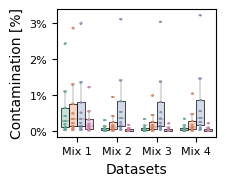

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch, Patch
from matplotlib.ticker import PercentFormatter


def boxplot_tools(df, x="Sample_Name", y="Contamination_Rate", hue="Method",
                  figsize=None, xlabel=None, ylabel=None, xlabel_fs=10, ylabel_fs=10,
                  xtick_fs=8, ytick_fs=8,
                  boxplot_width=0.8, whisker_lw=0.3, cap_lw=0.3, median_lw=0.3, box_lw=0.3,
                  palette=None, dot_size=1, dot_alpha=0.7, dot_lw=0.05, legend=True,
                  percent=False, percent_scale=None, percent_decimals=0,
                  save=False, fig_dir="./", file_path="boxplot.png"):
    if palette is None:
        palette = sns.color_palette("Set2")

    # ---- percent handling -------------------------------------------------
    if percent:
        df = df.copy()
        if percent_scale is None:
            # fractions (0-1) get scaled, values already in 0-100 are left alone
            percent_scale = 100 if df[y].max() <= 1.0 else 1
        if percent_scale != 1:
            df[y] = df[y] * percent_scale
    # -----------------------------------------------------------------------

    sample_order = sorted(df[x].unique())

    fig, ax = plt.subplots(figsize=figsize)

    if xlabel is None:
        xlabel = x
    if ylabel is None:
        ylabel = y
    if percent and not ylabel.rstrip().endswith(("%", "(%)")):
        ylabel = f"{ylabel} [%]"

    hue_order = list(df[hue].dropna().unique())

    ax = sns.boxplot(
        data=df, x=x, y=y,
        hue=hue, order=sample_order, hue_order=hue_order,
        palette=palette,
        width=boxplot_width, dodge=True, showfliers=False,
        ax=ax,
        whiskerprops={"linewidth": whisker_lw},
        capprops={"linewidth": cap_lw},
        medianprops={"linewidth": median_lw},
        legend=False,
        linewidth=box_lw
    )

    # Make only the box FILL transparent, keep borders opaque and thinner
    box_patches = [p for p in ax.patches if isinstance(p, PathPatch)]
    for p in box_patches:
        fc = p.get_facecolor()
        p.set_facecolor((fc[0], fc[1], fc[2], 0.4))
        p.set_edgecolor((0, 0, 0, 1))
        p.set_linewidth(0.5)

    sns.stripplot(
        data=df, x=x, y=y, hue=hue,
        order=sample_order, hue_order=hue_order,
        palette=palette, dodge=True, jitter=True,
        size=dot_size, alpha=dot_alpha, linewidth=dot_lw,
        legend=False, ax=ax
    )

    # Labels / ticks
    ax.set_ylabel(ylabel, fontsize=ylabel_fs)
    ax.set_xlabel(xlabel, fontsize=xlabel_fs)
    ax.tick_params(axis="x", labelsize=xtick_fs)
    ax.tick_params(axis="y", labelsize=ytick_fs)

    if percent:
        # data is now on a 0-100 scale, so xmax=100
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=percent_decimals))

    if legend:
        legend_handles = [
            Patch(facecolor=c, edgecolor="black", linewidth=0.5, alpha=1, label=lab)
            for lab, c in zip(hue_order, palette[:len(hue_order)])
        ]
        ax.legend(handles=legend_handles, title="Method", frameon=True,
                  fontsize=8, title_fontsize=8)

    plt.tight_layout()
    if save:
        plt.savefig(fig_dir / file_path, dpi=300)

    pos = ax.get_position()
    return ax, pos


df["Sample_ID"] = df["Sample_Name"].str.split(" ").apply(lambda v: "Mix " + v[1])

common = dict(
    x="Sample_ID", y="Contamination_Rate", hue="Method",
    xlabel="Datasets", ylabel="Contamination",
    figsize=mm_to_inches((60, 50)), legend=False, percent=True,
    save=True, fig_dir=fig_dir_comparison,
)

ax, pos = boxplot_tools(df, file_path="boxplot_contamination-rate_pct_datasets.pdf", **common)

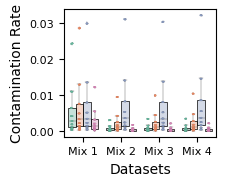

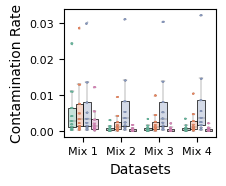

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch, Patch

def boxplot_tools(df, x = "Sample_Name", y = "Contamination_Rate", hue="Method", 
                  figsize=None, xlabel=None, ylabel=None, xlabel_fs = 10, ylabel_fs = 10, xtick_fs = 8, ytick_fs = 8,
                  boxplot_width=0.8, whisker_lw = 0.3, cap_lw = 0.3, median_lw = 0.3, box_lw=0.3,
                  palette = None, dot_size=1, dot_alpha=0.7, dot_lw=0.05, legend=True, 
                  save=False, fig_dir="./", file_path="boxplot.png"):
    if palette is None:
        palette = sns.color_palette("Set2")  
    sample_order = sorted(df[x].unique())

    fig, ax = plt.subplots(figsize=figsize)

    if xlabel is None:
        xlabel = x
    if ylabel is None:
        ylabel = y
    # Use one palette consistently
    hue_order = list(df[hue].dropna().unique())
    
    ax = sns.boxplot(
        data=df, x=x, y=y,
        hue=hue, order=sample_order, hue_order=hue_order,
        palette=palette,
        width=boxplot_width, dodge=True, showfliers=False,
        ax=ax,
        whiskerprops={"linewidth": whisker_lw},   # ← thinner whiskers
        capprops={"linewidth": cap_lw},       # ← thinner caps
        medianprops={"linewidth": median_lw},    # adjust median line
        legend=False,
        linewidth=box_lw
    )


    # Make only the box FILL transparent (alpha=0.4), keep borders opaque and thinner
    box_patches = [p for p in ax.patches if isinstance(p, PathPatch)]
    for p in box_patches:
        fc = p.get_facecolor()  # RGBA
        p.set_facecolor((fc[0], fc[1], fc[2], 0.4))     # transparent fill
        p.set_edgecolor((0, 0, 0, 1))                   # opaque border (black)
        p.set_linewidth(0.5)                            # thinner border

    sns.stripplot(
        data=df,
        x=x,
        y=y,
        hue=hue,
        order=sample_order,
        hue_order=hue_order,
        palette=palette,
        dodge=True,
        jitter=True,
        
        size=dot_size,
        alpha=dot_alpha,
        linewidth=dot_lw,      # ← remove edge thickness
        legend=False,
        ax=ax
    )

    # Labels / ticks
    ax.set_ylabel(ylabel, fontsize=ylabel_fs)
    ax.set_xlabel(xlabel, fontsize=xlabel_fs)
    ax.tick_params(axis="x", labelsize=xtick_fs)
    ax.tick_params(axis="y", labelsize=ytick_fs)

# # Remove seaborn's legend and add a custom opaque one
# if ax.legend_ is not None:
#     ax.legend_.remove()
    if legend:
        legend_handles = [
            Patch(
                facecolor=c,
                edgecolor="black",
                linewidth=0.5,   # ← thinner legend box border
                alpha=1,
                label=lab
            )
            for lab, c in zip(hue_order, palette[:len(hue_order)])
        ]

        ax.legend(
            handles=legend_handles,
            title="Method",
            frameon=True,
            fontsize=8,
            title_fontsize=8
        )
    plt.tight_layout()
    if save:
        plt.savefig(fig_dir / file_path, dpi=300)
        #print(f"Saved figure to {fig_dir / file_path}")

    pos = ax.get_position()
    return ax, pos
df["Sample_ID"] = df["Sample_Name"].str.split(" ").apply(lambda x: "Mix " + x[1])

ax, pos = boxplot_tools(df, x="Sample_ID", y="Contamination_Rate", hue="Method", xlabel="Datasets", ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_datasets.pdf")
boxplot_tools(df, x="Sample_ID", y="Contamination_Rate", hue="Method", xlabel="Datasets", ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_datasets.png");

In [37]:
df.columns

Index(['ID', 'Sample_Prefix', 'Total_Reads', 'Mixture', 'Replicate',
       'Human_Assigned', 'Mouse_Assigned', 'Amb_Assigned', 'Both_Assigned',
       'Neither_Assigned', 'Human_Human', 'Human_Mouse', 'Mouse_Mouse',
       'Mouse_Human', 'Amb_Human', 'Amb_Mouse', 'Both_Human', 'Both_Mouse',
       'Neither_Human', 'Neither_Mouse', 'Sample_Name', 'TP', 'TN', 'FP', 'FN',
       'Accuracy', 'Recall', 'FPR', 'Precision', 'F1', 'MCC', 'Human_Loss',
       'Contamination_Rate', 'Mouse_Leakage', 'Human_Ratio', 'Score', 'Method',
       'Unmapped', 'Unmapped_Human', 'Unmapped_Mouse', 'Amb_Human_Assigned',
       'Amb_Mouse_Assigned', 'Amb_Human_Human', 'Amb_Human_Mouse',
       'Amb_Mouse_Mouse', 'Amb_Mouse_Human', 'Sample_ID', 'Sequencing Depth'],
      dtype='object')

In [39]:
df.groupby(["Method", "Sample_ID"]).agg({"Human_Loss": "mean"})

Human_Loss
Method     Sample_ID            
ICRG       Mix 1        0.008988
           Mix 2        0.001816
           Mix 3        0.002163
           Mix 4        0.002480
Xengsort   Mix 1        0.033250
           Mix 2        0.007491
           Mix 3        0.007823
           Mix 4        0.007884
XenofilteR Mix 1        0.076766
           Mix 2        0.068222
           Mix 3        0.067197
           Mix 4        0.069138
bamcmp     Mix 1        0.021198
           Mix 2        0.005522
           Mix 3        0.005652
           Mix 4        0.006036

In [41]:
df.groupby(["Method", "Mixture"]).agg({"Contamination_Rate": "mean"})

Contamination_Rate
Method     Mixture                    
ICRG       10p                0.014549
           20p                0.006532
           30p                0.003825
           40p                0.002466
           50p                0.001646
           60p                0.001100
           70p                0.000707
           80p                0.000412
           90p                0.000183
Xengsort   10p                0.008511
           20p                0.003820
           30p                0.002237
           40p                0.001441
           50p                0.000964
           60p                0.000643
           70p                0.000415
           80p                0.000242
           90p                0.000108
XenofilteR 10p                0.004520
           20p                0.002018
           30p                0.001179
           40p                0.000759
           50p                0.000507
           60p                0.000338
           70p                0.000218
           80p                0.000127
           90p                0.000056
bamcmp     10p                0.030807
           20p                0.013928
           30p                0.008173
           40p                0.005272
           50p                0.003521
           60p                0.002352
           70p                0.001514
           80p                0.000883
           90p                0.000392

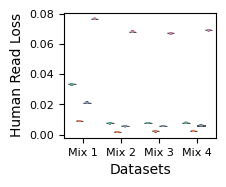

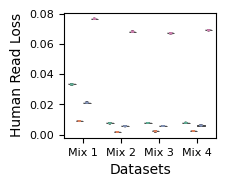

In [24]:
ax = boxplot_tools(df, x="Sample_ID", y="Human_Loss", hue="Method", xlabel="Datasets", ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_datasets.pdf")
ax = boxplot_tools(df, x="Sample_ID", y="Human_Loss", hue="Method", xlabel="Datasets", ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_datasets.png")

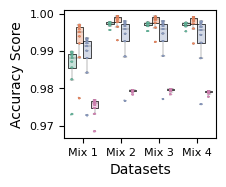

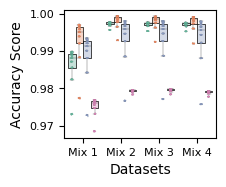

In [25]:
ax = boxplot_tools(df, x="Sample_ID", y="Score", hue="Method", xlabel="Datasets", ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_datasets.pdf")
ax = boxplot_tools(df, x="Sample_ID", y="Score", hue="Method", xlabel="Datasets", ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_datasets.png")

### Across Sequencing Depth

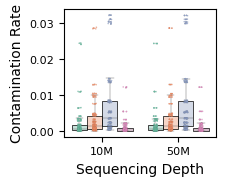

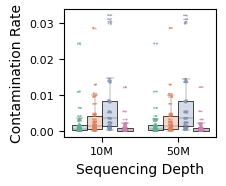

In [26]:
df["Sequencing Depth"] = (df["Total_Reads"] / 1_000_000 / 2).round().astype(int).astype(str) + "M"

ax = boxplot_tools(df, x="Sequencing Depth", y="Contamination_Rate", hue="Method", xlabel=None, ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_sequencing-depths.pdf")
ax = boxplot_tools(df, x="Sequencing Depth", y="Contamination_Rate", hue="Method", xlabel=None, ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_sequencing-depths.png")


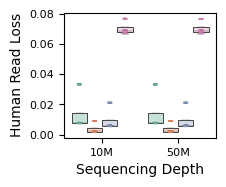

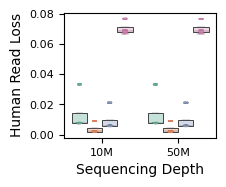

In [27]:

ax = boxplot_tools(df, x="Sequencing Depth", y="Human_Loss", hue="Method", xlabel=None, ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_sequencing-depths.pdf")
ax = boxplot_tools(df, x="Sequencing Depth", y="Human_Loss", hue="Method", xlabel=None, ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_sequencing-depths.png")


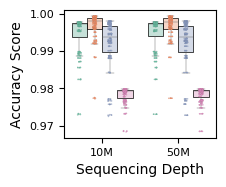

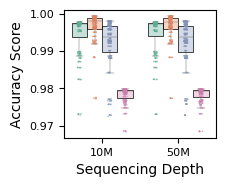

In [28]:

ax = boxplot_tools(df, x="Sequencing Depth", y="Score", hue="Method", xlabel=None, ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_sequencing-depths.pdf")
ax = boxplot_tools(df, x="Sequencing Depth", y="Score", hue="Method", xlabel=None, ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_sequencing-depths.png")


<Axes: xlabel='Human Content [%]', ylabel='Human Read Loss [%]'>

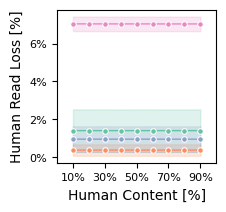

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.ticker import PercentFormatter


def lineplot_tools(df, x="Human_Ratio", y="Human_Loss", hue="Method",
                   ylabel=None, ylabel_fs=10, xlabel_fs=10, xlabel="Human Ratio",
                   tick_fs=8, figsize=None, palette=None, errorbar="sd",
                   marker="o", linewidth=1, markersize=4, legend=True, pos=None,
                   xlim=(0, 1), n_xticks=5,
                   percent=False, percent_scale=None, percent_decimals=0,
                   x_percent=True, x_percent_xmax=1, x_percent_decimals=0,
                   save=False, fig_dir="./", file_path="lineplot.png"):

    # ---- percent handling (y-axis) ---------------------------------------
    if percent:
        df = df.copy()
        if percent_scale is None:
            percent_scale = 100 if df[y].max() <= 1.0 else 1
        if percent_scale != 1:
            df[y] = df[y] * percent_scale
    # -----------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=figsize)

    if pos is not None:
        ax.set_position(pos)

    if xlabel is None:
        xlabel = x
    if ylabel is None:
        ylabel = y
    if percent and not ylabel.rstrip().endswith("%"):
        ylabel = f"{ylabel} [%]"
    if palette is None:
        palette = sns.color_palette("Set2")

    hue_order = list(df[hue].dropna().unique())

    sns.lineplot(
        data=df, x=x, y=y, hue=hue, hue_order=hue_order, palette=palette,
        errorbar=errorbar, marker=marker, linewidth=linewidth,
        markersize=markersize, ax=ax, legend=legend,
    )

    ax.set_xlim(*xlim)
    if n_xticks:
        lo, hi = df[x].min(), df[x].max()
        ax.set_xticks(np.linspace(lo, hi, n_xticks))
    if x_percent:
        ax.xaxis.set_major_formatter(
            PercentFormatter(xmax=x_percent_xmax, decimals=x_percent_decimals)
        )

    if percent:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=percent_decimals))

    ax.set_ylabel(ylabel, fontsize=ylabel_fs)
    ax.set_xlabel(xlabel, fontsize=xlabel_fs)
    ax.tick_params(axis="both", labelsize=tick_fs)

    if save:
        fig.savefig(Path(fig_dir) / file_path, bbox_inches=None)

    return ax



lineplot_tools(df, x = "Human_Ratio", y="Human_Loss", hue="Method", xlabel="Human Content [%]", ylabel="Human Read Loss",
    legend=False, percent=True, figsize=mm_to_inches((60, 60)), pos=pos,
    save=True, fig_dir=fig_dir_comparison, file_path="lineplot_human-read_loss_pct_human-ratio.svg")

<Axes: xlabel='Human Content [%]', ylabel='Contamination Rate [%]'>

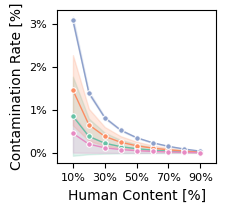

In [30]:
lineplot_tools(df, x="Human_Ratio", y="Contamination_Rate", hue="Method", xlabel = "Human Content [%]", ylabel="Contamination Rate", 
               legend=False, figsize=mm_to_inches((60, 60)), save=True, pos = pos, percent=True,
               fig_dir = fig_dir_comparison, file_path="lineplot_contamination-rate_pct_human-ratio.svg")

<Axes: xlabel='Human Content [%]', ylabel='Accuracy Score'>

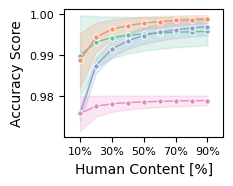

In [24]:
lineplot_tools(df, x="Human_Ratio", y="Score", hue="Method", ylabel="Accuracy Score", xlabel="Human Content [%]",
               legend=False, figsize=mm_to_inches((60, 50)), save=True, pos = pos, 
               fig_dir = fig_dir_comparison, file_path="lineplot_performance-score_human-ratio.pdf")
